Results:
Gamma (intercept) = 1.6072e-04 cal/(mol·K²)
Alpha (slope) = 1.1531e-05 cal/(mol·K⁴)

fermi energy from exp gamma: 5.2572 eV


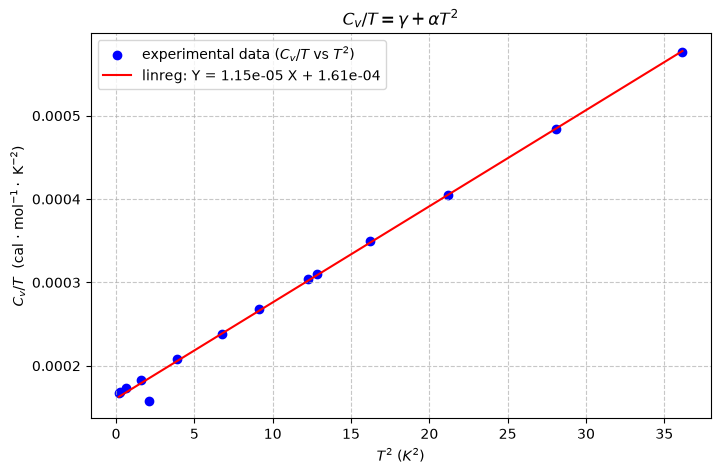

In [7]:
import numpy as np
import matplotlib.pyplot as plt

T = np.array([0.418, 0.517, 0.787, 1.252, 1.452, 1.968, 2.603, 
              3.02, 3.498, 3.579, 4.023, 4.606, 5.301, 6.013])

# applying 10^-2 (cal / mol*K) factor
Cv = np.array([0.007, 0.0087, 0.0136, 0.0229, 0.0229, 0.041, 0.0621, 
               0.0809, 0.1065, 0.1109, 0.1407, 0.1867, 0.2567, 0.3464]) * 1e-2

# transforming vars
X = T**2
Y = Cv / T

# order 1 polyfit (linear)
alpha, gamma = np.polyfit(X, Y, 1)

print("Results:")
print(f"Gamma (intercept) = {gamma:.4e} cal/(mol·K²)")
print(f"Alpha (slope) = {alpha:.4e} cal/(mol·K⁴)")

# Fermi energy calculation
R = 1.987        # gas constant in cal/(mol*K)
k_B = 8.617e-5   # Boltzmann constant in eV/K

# gamma = (pi^2 / 2) * (R * k_B) / Ef
Ef = (np.pi**2 * R * k_B) / (2 * gamma)
print("\n"+fr"fermi energy from exp gamma: {Ef:.4f} eV")

# graph
plt.figure(figsize=(8, 5))
plt.scatter(X, Y, color='blue', label=r'experimental data ($C_v/T$ vs $T^2$)')
plt.plot(X, alpha * X + gamma, color='red', label=fr'linreg: Y = {alpha:.2e} X + {gamma:.2e}')
plt.xlabel(r'$T^2$ ($K^2$)')
plt.ylabel(r'$C_v / T$  (cal $\cdot$ mol$^{-1} \cdot$ K$^{-2}$)')
plt.title(r'$C_v/T = \gamma + \alpha T^2$')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()